# **Intro to OpenCV**

![rainbow](https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/main/assets/rainbow-divider.png)

# 📖 TABLE OF CONTENTS

- [What is a Digital Image?](#What-is-a-Digital-Image?)
- [Install Dependencies](#Install-Dependencies)
- [Intro to OpenCV](#Intro-to-OpenCV)
- [Import Libraries](#Import-Libraries)
- [Read Images](#Read-Images)
- [Image Properties](#Image-Properties)
- [Display Images](#Display-Images)
- [Save Images](#Save-Images)
- [Change Color Space](#Change-Color-Space)
- [Resize Images](#Resize-Images)
- [Display Text in Images](#Display-Text-in-Images)
- [Split and Merge Channels](#Split-and-Merge-Channels)
- [Image Smoothing / Blurring](#Image-Smoothing-/-Blurring)
  - [1. Mean Blurring](#1.-Mean-Blurring)
  - [2. Median Blurring](#2.-Median-Blurring)
  - [3. Gaussian Blurring](#3.-Gaussian-Blurring)
  - [4. Bilateral Blurring](#4.-Bilateral-Blurring)
- [Histograms](#Histograms)
- [Thresholding](#Thresholding)
  - [1. Simple Thresholding](#1.-Simple-Thresholding)
  - [2. Otsu Thresholding](#2.-Otsu-Thresholding)
  - [3. Adaptive Thresholding](#3.-Adaptive-Thresholding)
- [Edge Detection](#Edge-Detection)
  - [1. Edge Detection using Gradient](#1.-Edge-Detection-using-Gradient)
    - [1. 1D Edge Detection](#1.-1D-Edge-Detection)
    - [2. Discrete Gradient Operator](#2.-Discrete-Gradient-Operator)
  - [2. Edge Detection using Laplacian](#2.-Edge-Detection-using-Laplacian)
  - [3. Canny Edge Detection](#3.-Canny-Edge-Detection)
- [Contour Detection](#Contour-Detection)
  - [1. cv2.findContours()](#1.-cv2.findContours())
    - [1. Contour Retrieval Modes](#1.-Contour-Retrieval-Modes)
    - [2. Contour Approximation Modes](#2.-Contour-Approximation-Modes)

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# What is a Digital Image?

An image is nothing more than a collection of pixels and their intensities. An image may be defined as a two-dimensional function, f (x,y), where x and y are spatial
(plane) coordinates, and the amplitude of f at any pair of coordinates (x, y) is called the
intensity or gray level of the image at that point.

A 2D image can be represented as a matrix as below:

$
f(x, y) = \begin{bmatrix}
f(0, 0) & f(0, 1) & ... & f(0, N-1) \\
f(1, 0) & f(1, 1) & ... & f(1, N-1) \\
. & . & . & . \\
. & . & . & . \\
. & . & . & . \\
f(M-1, 0) & f(M-1, 1) & ... & f(M-1, N-1)
\end{bmatrix}
$

where we have:

- Each element f(x, y) represents the intensity value at pixel coordinates (x, y).
- Rows correspond to the y-coordinate, increasing from top to bottom.
- Columns correspond to the x-coordinate, increasing from left to right.
- M is the total number of rows (height of the image).
- N is the total number of columns (width of the image).

In NumPy, a 2D image is represented as a multi-dimensional array. The dimensions correspond to:

- **First dimension:** Rows (y-coordinate).
- **Second dimension:** Columns (x-coordinate).

In [ ]:
# Assuming M = 3, N = 4
image_data = np.array([
    [100, 200, 150, 50],  # Row 0 (y = 0)
    [80, 120, 90, 60],   # Row 1 (y = 1)
    [50, 70, 110, 30]   # Row 2 (y = 2)
])

# Accessing a specific element at the second row (y = 1) and third column (x = 2)
print(f"Element: \n{image_data[1, 2]}")

# Slicing the array to get sub-array consisting of the first 2 rows and the first 3 columns
print(f"Sub-array: \n{image_data[:2, :3]}")

Element: 
90
Sub-array: 
[[100 200 150]
 [ 80 120  90]]


In the above example, `image_data[1, 2]` would access the intensity value at pixel coordinates (2, 1) (x = 2, y = 1) which is 90.

Slicing selects a sub-array. The slicing notation [:2, :3] works as follows:

- `:2` means take all rows from the start up to (but not including) row index 2.
- `:3` means take all columns from the start up to (but not including) column index 3.

This results in selecting the sub-array consisting of the first 2 rows and the first 3 columns.

In the below figure, a Grayscale image is shown as a 2-D numerical array (the numbers 0, .5, and 1 represent black, gray, and white respectively):

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-02.jpg" width="500">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>Image shown as a 2-D numerical array</em>
    </td>
  </tr>
</table>

We can create an RGB image by stacking 2-D numerical arrays corresponding to Red, Green and Blue channels as shown below:

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-03.jpg" width="500">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>Formation of RGB Image from 2-D numerical arrays for Red, Green and Blue</em>
    </td>
  </tr>
</table>

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-04.jpg">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>Formation of RGB Image from 2-D numerical arrays for Red, Green and Blue</em>
    </td>
  </tr>
</table>

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Install Dependencies

In [ ]:
!pip3 install opencv-python matplotlib

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Intro to OpenCV

OpenCV (Open Source Computer Vision Library) is an open-source library for computer
vision and machine learning. It was initiated by Intel and has been primarily supported by
the company since its inception. The purpose of OpenCV is to offer a standardized
infrastructure for computer vision applications, thereby promoting the integration of
machine perception into commercial products. Written in the C++ programming
language, OpenCV also has wrappers available in other languages such as Python, Java,
and Matlab.

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Import Libraries

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Read Images

Generally, we access images in the RGB color format, as every color perceivable by the human eye is a combination of these three colors: Red, Green, and Blue. However, the initial developers
at OpenCV chose the BGR color format instead of RGB. This decision was influenced by the popularity of the BGR format among software providers and camera manufacturers at the time.

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-05.jpg" width="300">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>Example Image</em>
    </td>
  </tr>
</table>

array([[[ 38,   3,   0],
        [ 70,  12,   7],
        [ 96,   0,   0],
        ...,
        [  0,  20,  21],
        [  0,  20,  21],
        [  0,  20,  21]],

       [[ 65,   6,   4],
        [112,  29,  27],
        [152,  22,  22],
        ...,
        [118, 238, 237],
        [118, 239, 235],
        [118, 238, 237]],

       [[101,   0,   0],
        [160,  30,  30],
        [208,  29,  30],
        ...,
        [ 54, 246, 239],
        [ 54, 247, 237],
        [ 54, 246, 239]],

       ...,

       [[  0,  55,   0],
        [ 57, 163,  56],
        [ 35, 193,  27],
        ...,
        [ 16,   6, 250],
        [ 16,   6, 250],
        [ 16,   6, 250]],

       [[  0,  55,   0],
        [ 57, 163,  56],
        [ 35, 193,  27],
        ...,
        [ 16,   6, 250],
        [ 16,   6, 250],
        [ 16,   6, 250]],

       [[  0,  55,   0],
        [ 57, 163,  56],
        [ 35, 193,  27],
        ...,
        [ 16,   6, 250],
        [ 16,   6, 250],
        [ 16,   6, 250]]], dtype=uint8)
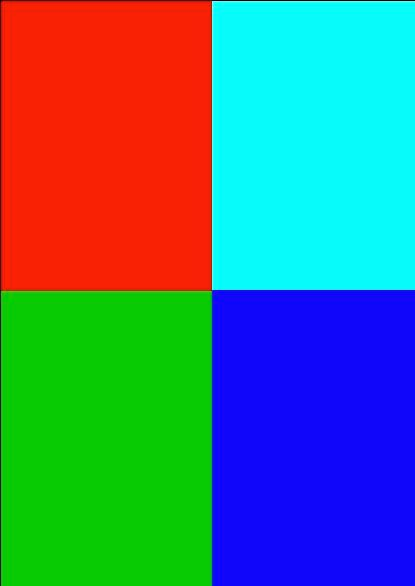

In [ ]:
# Read and display images
# cv2.imread(path, flag)
img_path = "data/images/Intro_to_OpenCV-05.jpg"
img = cv2.imread(img_path)
img

In [ ]:
print(img)

[[[ 38   3   0]
  [ 70  12   7]
  [ 96   0   0]
  ...
  [  0  20  21]
  [  0  20  21]
  [  0  20  21]]

 [[ 65   6   4]
  [112  29  27]
  [152  22  22]
  ...
  [118 238 237]
  [118 239 235]
  [118 238 237]]

 [[101   0   0]
  [160  30  30]
  [208  29  30]
  ...
  [ 54 246 239]
  [ 54 247 237]
  [ 54 246 239]]

 ...

 [[  0  55   0]
  [ 57 163  56]
  [ 35 193  27]
  ...
  [ 16   6 250]
  [ 16   6 250]
  [ 16   6 250]]

 [[  0  55   0]
  [ 57 163  56]
  [ 35 193  27]
  ...
  [ 16   6 250]
  [ 16   6 250]
  [ 16   6 250]]

 [[  0  55   0]
  [ 57 163  56]
  [ 35 193  27]
  ...
  [ 16   6 250]
  [ 16   6 250]
  [ 16   6 250]]]


![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Image Properties

In [ ]:
type(img)

numpy.ndarray

In [ ]:
# Resolution of image, it depicts the no of rows, the no of columns, and the no of channels.
img.shape

(586, 415, 3)

In [ ]:
img.size

729570

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Display Images

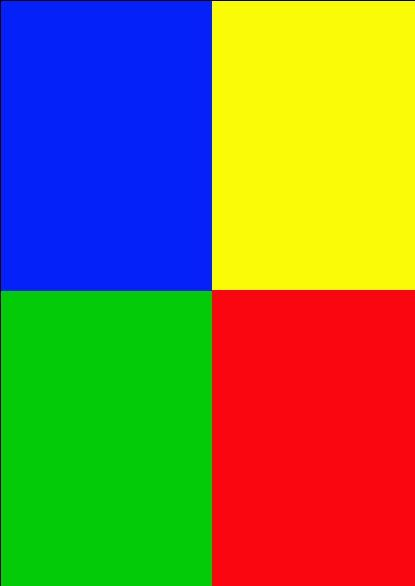

In [ ]:
# Display image using cv2

# To be used in Python code
# cv2.imshow("Image Display",img)
# cv2.waitKey(0)
# cv2.destroyAllWindows()

# To be used in Jupyter Notebook
from google.colab.patches import cv2_imshow
cv2_imshow(img)

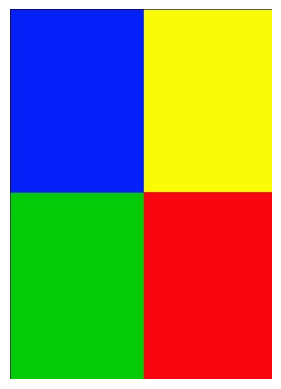

In [ ]:
# Display image using matplotlib
rgb_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert image from BGR to RGB format
plt.imshow(rgb_img)
plt.axis('off')
plt.show()

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Save Images

In [ ]:
# Saving an image
# cv2.imwrite(<filename>, <image>)

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Change Color Space

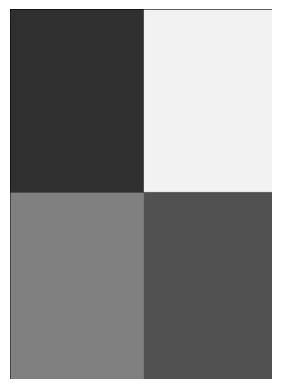

In [ ]:
# Changing color space

gray_img =  cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

plt.imshow(gray_img, cmap='gray')  # Instruct Matplotlib to handle image as Grayscale
plt.axis('off')
plt.show()

Converting an RGB image into a Grayscale image involves a weighted sum of the RGB color channels. The typical formula for converting an RGB image to Grayscale is given below:

**Gray = 0.2989 $\times$ Red + 0.5870 $\times$ Green + 0.1140 $\times$ Blue**

This formula represents the luminance of each pixel in the grayscale image, where the coefficients (0.2989, 0.5870, and 0.1140) represent the perceived brightness of each color channel to the human eye. These coefficients are based on the luminosity formula used in television systems.

So, for each pixel in the RGB image, you take the corresponding Red, Green, and Blue values, multiply them by their respective coefficients, and sum the results to obtain the grayscale intensity value for that pixel. This process is applied to every pixel in the image to generate the grayscale representation.

In [ ]:
def rgb_to_gray(rgb_image):
    # Extract the dimensions of the input image
    height, width, _ = rgb_image.shape

    # Create a grayscale image with the same dimensions as the input image
    gray_image = np.zeros((height, width), dtype=np.uint8)

    # Iterate over each pixel in the image
    for y in range(height):
        for x in range(width):
            # Extract the RGB values for the current pixel
            red, green, blue = rgb_image[y, x]

            # Convert RGB to grayscale using the formula
            gray_value = int(0.2989 * red + 0.5870 * green + 0.1140 * blue)

            # Set the grayscale value for the current pixel in the output image
            gray_image[y, x] = gray_value

    return gray_image

# Load the RGB image
rgb_image = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Convert RGB image to Grayscale
gray_image = rgb_to_gray(rgb_image)

# Display the original RGB image and the Grayscale image
cv2.imshow('RGB Image', rgb_image)
cv2.imshow('Grayscale Image', gray_image)
cv2.waitKey(0)
cv2.destroyAllWindows()

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Resize Images

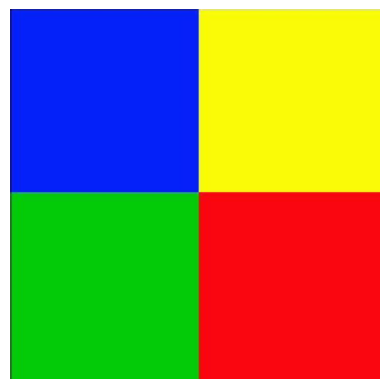

In [ ]:
# Resizing the image
resized_img = cv2.resize(rgb_img, (200, 200))

plt.imshow(resized_img)
plt.axis('off')
plt.show()

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Display Text in Images

In [ ]:
# Displaying text on the image
# img_with_txt = cv2.putText(img, 'Text', (10, 10), cv2.FONT_HERSHEY_COMPLEX, 4, (100, 100, 100), 2)

# plt.imshow(img_with_txt)
# plt.axis('off')
# plt.show()

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Split and Merge Channels

In [ ]:
print(img.shape)
print("Top left", img[0,0])  # Top left pixel
print("Top right", img[0, 400])  # Top right pixel
print("Bottom Left", img[580, 0])  # Bottom left pixel
print("Bottom right", img[580, 400])  # Bottom right pixel

(586, 415, 3)
Top left [38  3  0]
Top right [ 0 20 21]
Bottom Left [ 0 55  0]
Bottom right [ 16   6 250]


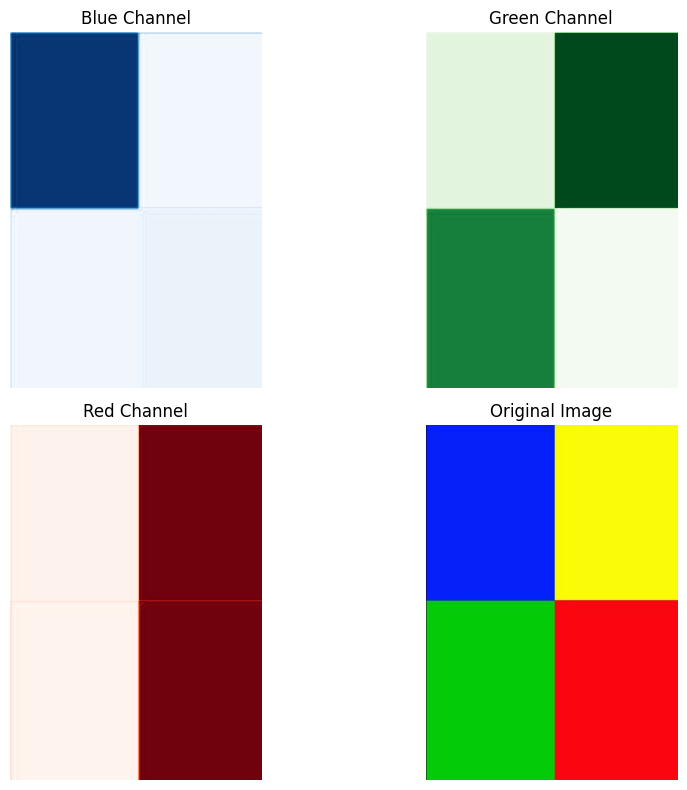

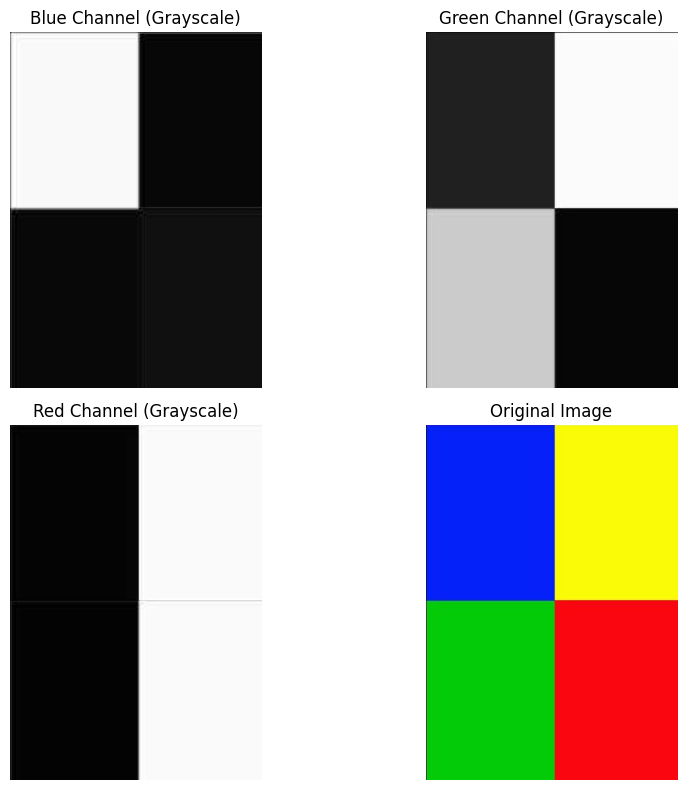

In [ ]:
# Split channels
blue = img[:, :, 0]  # Get only blue pixels (BGR => B = 0)
green = img[:, :, 1]  # Get only green pixels (BGR => G = 1)
red = img[:, :, 2]  # Get only red pixels (BGR => R = 2)

# Plotting the images
plt.figure(figsize=(10, 8))

# Displaying the blue channel
plt.subplot(2, 2, 1)
plt.imshow(blue, cmap='Blues')
plt.title('Blue Channel')
plt.axis('off')

# Displaying the green channel
plt.subplot(2, 2, 2)
plt.imshow(green, cmap='Greens')
plt.title('Green Channel')
plt.axis('off')

# Displaying the red channel
plt.subplot(2, 2, 3)
plt.imshow(red, cmap='Reds')
plt.title('Red Channel')
plt.axis('off')

# Displaying the original image
plt.subplot(2, 2, 4)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.tight_layout()
plt.show()

# Plotting the images as grayscale
plt.figure(figsize=(10, 8))

# Displaying the blue channel as grayscale
plt.subplot(2, 2, 1)
plt.imshow(blue, cmap='gray')
plt.title('Blue Channel (Grayscale)')
plt.axis('off')

# Displaying the green channel as grayscale
plt.subplot(2, 2, 2)
plt.imshow(green, cmap='gray')
plt.title('Green Channel (Grayscale)')
plt.axis('off')

# Displaying the red channel as grayscale
plt.subplot(2, 2, 3)
plt.imshow(red, cmap='gray')
plt.title('Red Channel (Grayscale)')
plt.axis('off')

# Displaying the original image
plt.subplot(2, 2, 4)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.tight_layout()
plt.show()

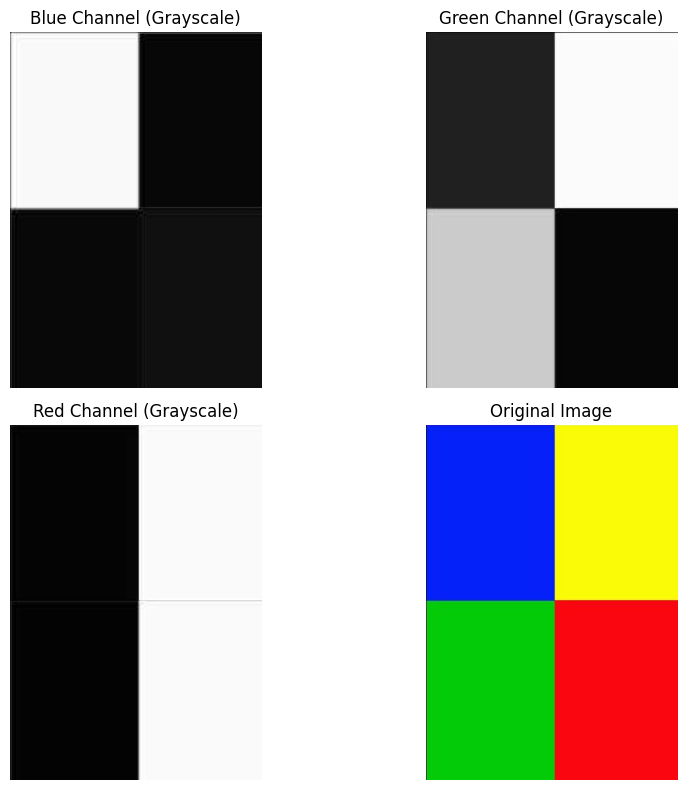

In [ ]:
# Split all channels at once
b,g,r = cv2.split(img)

# Plotting the images as grayscale
plt.figure(figsize=(10, 8))

# Displaying the blue channel as grayscale
plt.subplot(2, 2, 1)
plt.imshow(b, cmap='gray')
plt.title('Blue Channel (Grayscale)')
plt.axis('off')

# Displaying the green channel as grayscale
plt.subplot(2, 2, 2)
plt.imshow(g, cmap='gray')
plt.title('Green Channel (Grayscale)')
plt.axis('off')

# Displaying the red channel as grayscale
plt.subplot(2, 2, 3)
plt.imshow(r, cmap='gray')
plt.title('Red Channel (Grayscale)')
plt.axis('off')

# Displaying the original image
plt.subplot(2, 2, 4)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')

plt.tight_layout()
plt.show()

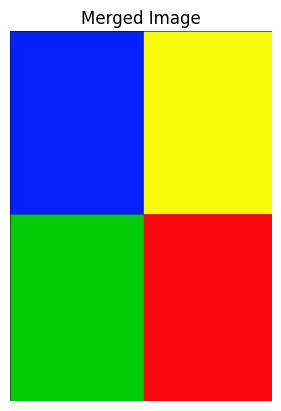

In [ ]:
# Merge each image into bgr
img_merged = cv2.merge((b,g,r))

plt.imshow(cv2.cvtColor(img_merged, cv2.COLOR_BGR2RGB))
plt.title('Merged Image')
plt.axis('off')
plt.show()

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Image Smoothing / Blurring

In Image Processing, Blurring is the process of making an image less sharp and reducing its detail. It does this **by making color transitions between edges smooth instead of sudden, and by averaging out rapid pixel intensity changes.** These rapid changes in pixel intensities are not defining the actual structure of the objects, but is behaving as a noise.

Smoothing / Blurring is mainly used to reduce these kinds of noise of the image. It is achieved by averaging the pixels in a region with its neighbors. Here are the common types of blurring techniques:

- Mean Blurring
- Median Blurring
- Gaussian Blurring
- Bilateral Blurring

## 1. Mean Blurring

- **Concept:** It is the simplest type of smoothing operation. This operation takes the average of pixels and replace the central pixel with this average. The average blurring 3x3 kernel $\implies$
$\frac {1}{9}\begin{bmatrix}
1 & 1 & 1 \\
1 & 1 & 1 \\
1 & 1 & 1
\end{bmatrix}
$

- **Function:**
    - `cv2.blur`

- **Parameters:**
    - `src`: Input image
    - `ksize`: Kernel size (width and height)

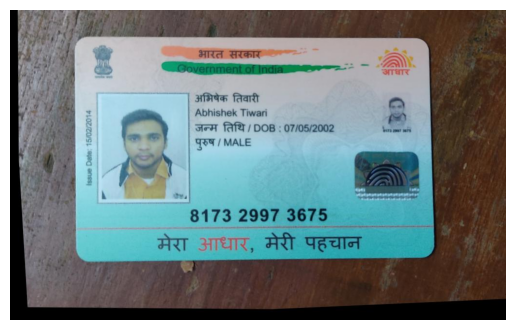

In [ ]:
img = cv2.imread("data/images/Intro_to_OpenCV-06.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure()
plt.imshow(img)
plt.axis('off')
plt.show()

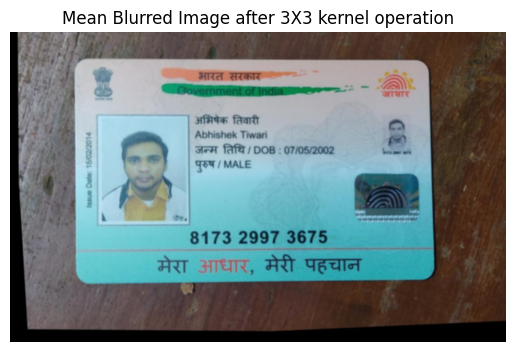

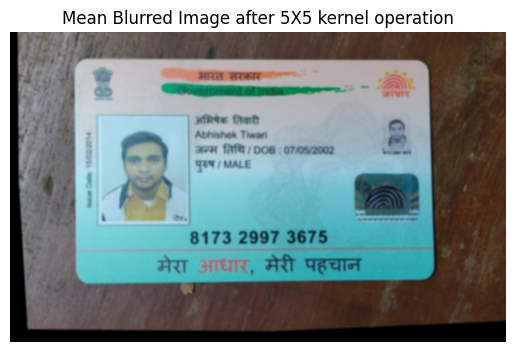

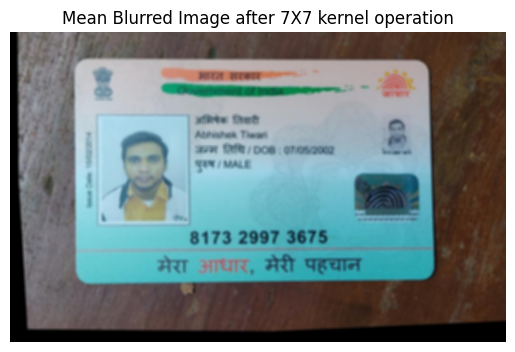

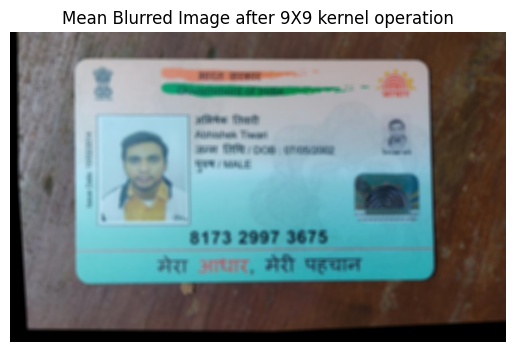

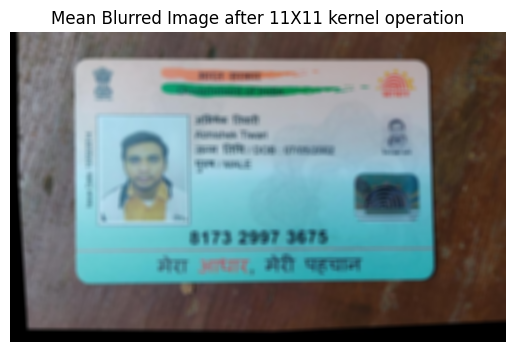

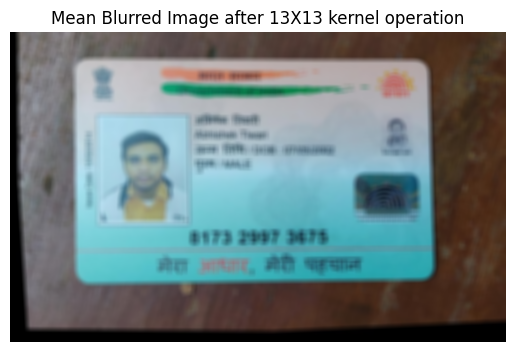

In [ ]:
# Creating mean filter kernel
def mean_kernel(size):
    mk = np.ones((size, size), dtype = np.float32)/(size**2)
    return mk

# Performing Mean Blur
for size in range(3, 14, 2):
    blur_img = cv2.filter2D(img , -1, mean_kernel(size))
    plt.figure()
    plt.imshow(blur_img)
    plt.title(f"Mean Blurred Image after {size}X{size} kernel operation")
    plt.axis('off')
    plt.show()

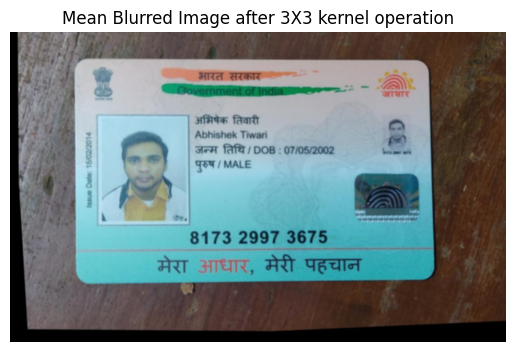

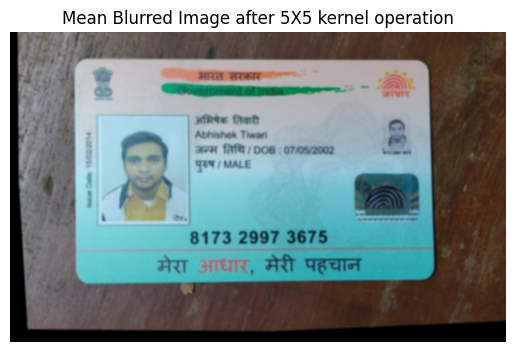

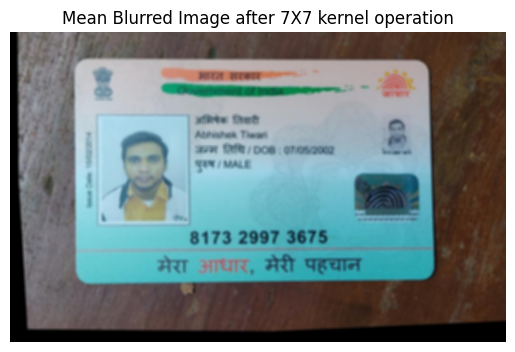

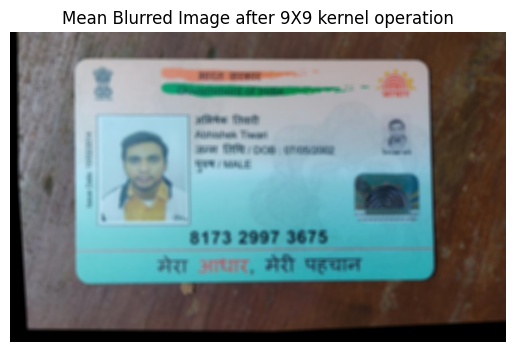

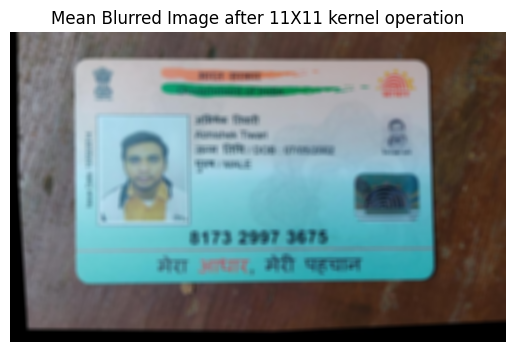

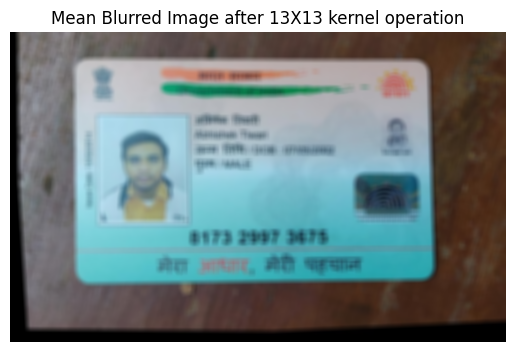

In [ ]:
for size in range(3, 14, 2):
    blur_img = cv2.blur(img, (size, size))
    plt.figure()
    plt.imshow(blur_img)
    plt.title(f"Mean Blurred Image after {size}X{size} kernel operation")
    plt.axis('off')
    plt.show()

## 2. Median Blurring

- **Concept:** Replaces each pixel with the median of its neighbors within a specified kernel size. Effective for removing salt-and-pepper noise.

- **Function:** `cv2.medianBlur()`

- **Parameters:**
    - `src`: Input image
    - `ksize`: Kernel size (must be an odd integer)

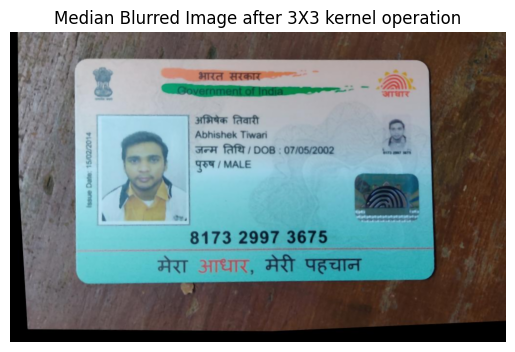

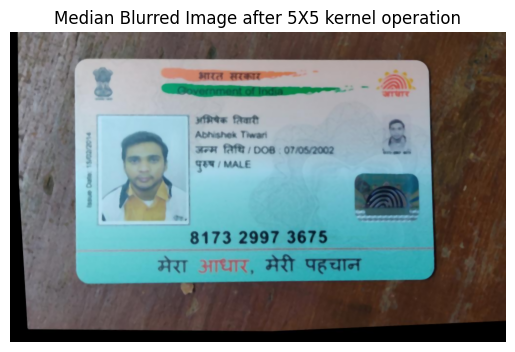

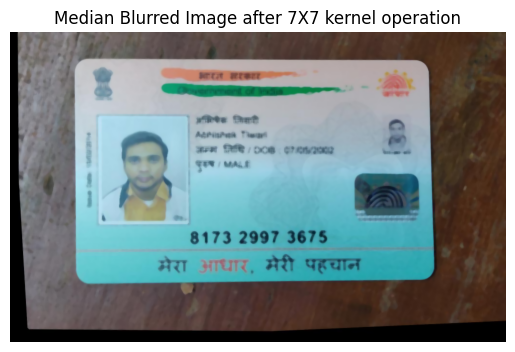

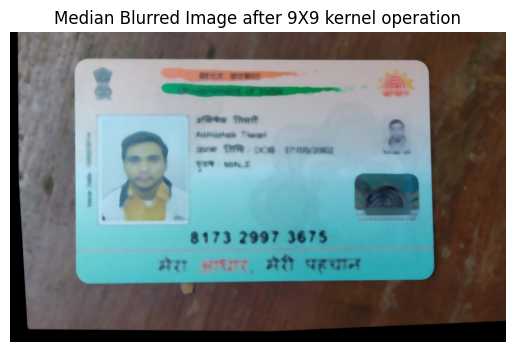

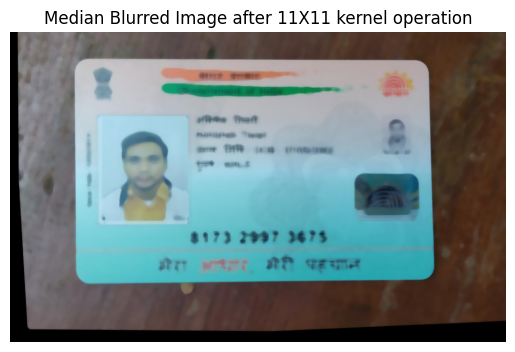

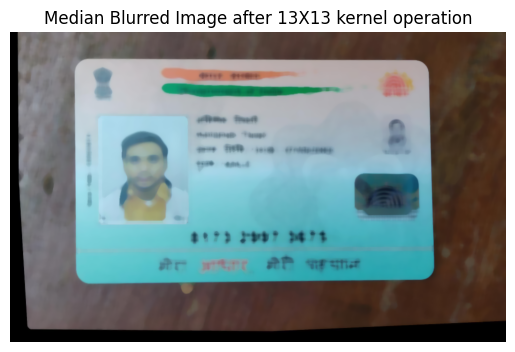

In [ ]:
for size in range(3, 14, 2):
    blur_img = cv2.medianBlur(img, size)
    plt.figure()
    plt.imshow(blur_img)
    plt.title(f"Median Blurred Image after {size}X{size} kernel operation")
    plt.axis('off')
    plt.show()

## 3. Gaussian Blurring

- **Concept:** Uses a Gaussian kernel to weight pixels based on their distance from the center.

- **Function:** cv2.GaussianBlur()

- **Parameters:**
    - `src`: Input image
    - `ksize`: Kernel size (width and height)
    `sigmaX`: Standard deviation in the x-direction
    `sigmaY`: Standard deviation in the y-direction (if omitted, equals sigmaX)

It is a method of blurring the image through the use of Gaussian Distribution. Gaussian Distribution is shown below:

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-07.jpg">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>Gaussian distribution</em>
    </td>
  </tr>
</table>

Imagine that this distribution is superimposed over a group of pixels in an image. It should be apparent looking at this graph, that if we took a weighted average of a pixel's values and the height of the curve at that point, the pixels in the center of the group would contribute most significantly to the resulting value.

Formula for Gaussian distribution is given below:

$G(x, y) = \frac {1}{2 \pi \sigma^2} e^{- \frac {x^2+y^2}{2 \sigma^2}}$

Consider the 7x7 kernel for the Gaussian blur filter below:

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-08.jpg">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>7x7 kernel for the Gaussian blur filter</em>
    </td>
  </tr>
</table>

Imagine that plot laid over the kernel for the Gaussian blur filter. The height of the plot corresponds to the weight given to the underlying pixel in the kernel i.e. the pixels close to the centre become more important to the filtered pixel colour than the pixels close to the outer limits of the kernel. The shape of the Gaussian function is controlled via its standard deviation $\sigma$. A large sigma value results in a flatter shape, while a smaller sigma value results in a more pronounced peak.

To illustrate the blurring process, consider the blue channel colour values from the 7x7 region of an image:

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-09.jpg">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>Blue channel colour values from the 7x7 region of an image</em>
    </td>
  </tr>
</table>

The filter is going to determine the new blue channel value for the centre pixel - the one that currently has the value 86. The filter calculates a weighted average of all the blue channel values in the kernel giving higher weight to the pixels near the centre of the kernel.

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-10.jpg">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>Weighted average of all the blue channel values in the kernel</em>
    </td>
  </tr>
</table>

This weighted average becomes the new value for the centre pixel (3, 3). The same process would be used to determine the green and red channel values, and then the kernel would be moved over to apply the filter to the next pixel in the image.

7x7 Gaussian Kernel: 
[[1.94254715e-07 9.65682564e-06 1.00626434e-04 2.19788338e-04
  1.00626434e-04 9.65682564e-06 1.94254715e-07]
 [9.65682564e-06 4.80061867e-04 5.00235953e-03 1.09261577e-02
  5.00235953e-03 4.80061867e-04 9.65682564e-06]
 [1.00626434e-04 5.00235953e-03 5.21257832e-02 1.13853178e-01
  5.21257832e-02 5.00235953e-03 1.00626434e-04]
 [2.19788338e-04 1.09261577e-02 1.13853178e-01 2.48678204e-01
  1.13853178e-01 1.09261577e-02 2.19788338e-04]
 [1.00626434e-04 5.00235953e-03 5.21257832e-02 1.13853178e-01
  5.21257832e-02 5.00235953e-03 1.00626434e-04]
 [9.65682564e-06 4.80061867e-04 5.00235953e-03 1.09261577e-02
  5.00235953e-03 4.80061867e-04 9.65682564e-06]
 [1.94254715e-07 9.65682564e-06 1.00626434e-04 2.19788338e-04
  1.00626434e-04 9.65682564e-06 1.94254715e-07]]


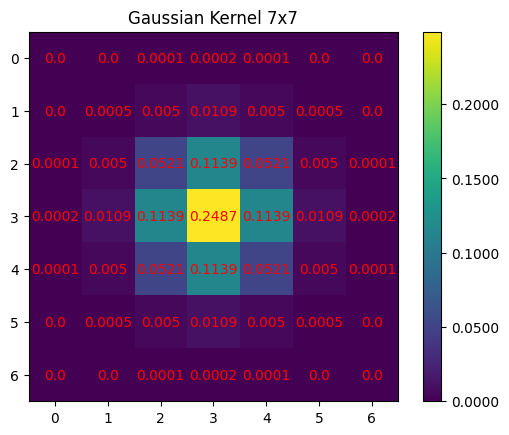

In [ ]:
def gaussian_kernel(sigma, kernel_size):
    kernel = np.zeros((kernel_size, kernel_size))
    center = kernel_size // 2
    normalization_factor = 1 / (2 * np.pi * sigma**2)
    # print(center)

    for i in range(kernel_size):
        for j in range(kernel_size):
            # x and y represent the distance of the current pixel from the center of the kernel
            # in the horizontal and vertical directions respectively
            x = i - center
            y = j - center
            kernel[i, j] = normalization_factor*np.exp(-(x**2 + y**2) / (2 * sigma**2))

    # Normalize the kernel
    kernel /= np.sum(kernel)

    return kernel

# Example usage
sigma = 0.8
kernel_size = 7
gaussian_kernel_7x7 = gaussian_kernel(sigma, kernel_size)
print(f"7x7 Gaussian Kernel: \n{gaussian_kernel_7x7}")

# Round values to 4 decimal places
kernel_rounded = np.round(gaussian_kernel_7x7, 4)

# Plot the kernel as a heatmap with values
fig, ax = plt.subplots()
im = ax.imshow(kernel_rounded, cmap='viridis', interpolation='nearest')

# Add text annotations to each cell
for i in range(kernel_size):
    for j in range(kernel_size):
        text = ax.text(j, i, str(kernel_rounded[i, j]),
                       ha="center", va="center", color="r")

ax.set_title("Gaussian Kernel 7x7")
plt.colorbar(im, format='%.4f')
plt.show()

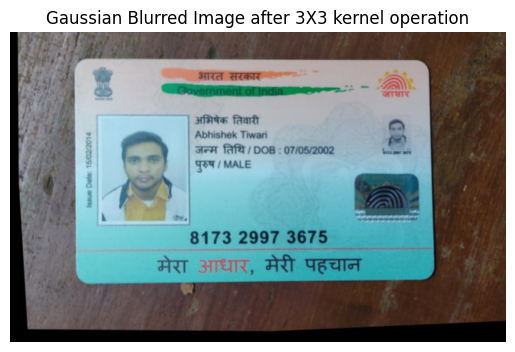

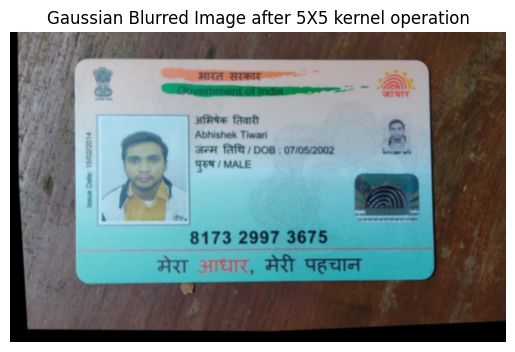

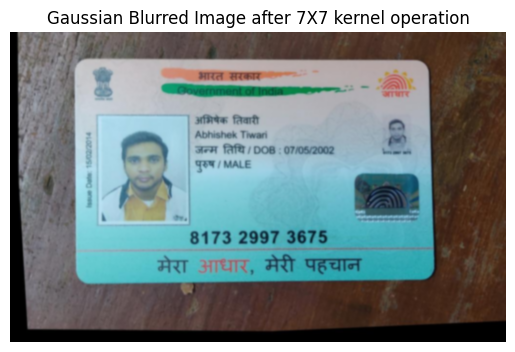

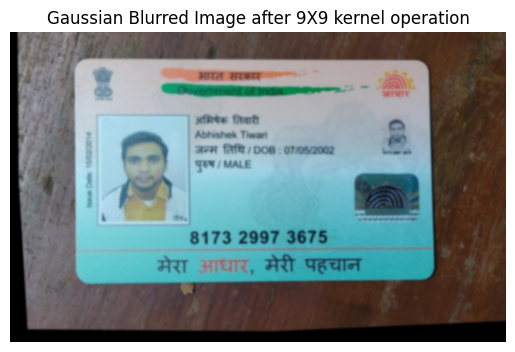

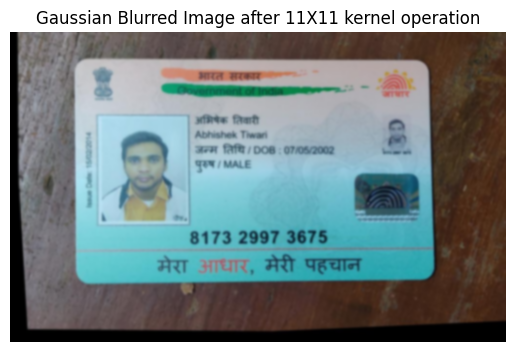

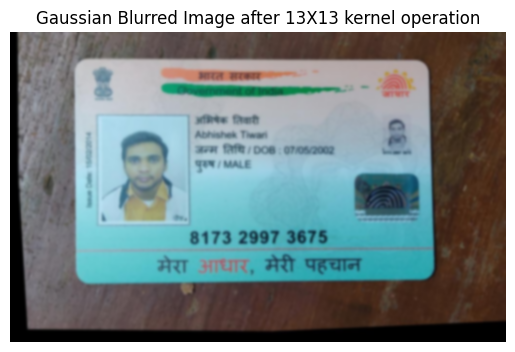

In [ ]:
for size in range(3, 14, 2):
    blur_img = cv2.GaussianBlur(img, (size, size), 0)
    plt.figure()
    plt.imshow(blur_img)
    plt.title(f"Gaussian Blurred Image after {size}X{size} kernel operation")
    plt.axis('off')
    plt.show()

## 4. Bilateral Blurring

- **Concept:** Preserves edges while reducing noise. Uses a Gaussian filter in both color-space and spatial domain.

- **Function:** `cv2.bilateralFilter()`

- **Parameters:**
    - `src`: Input image
    - `d`: Diameter of each pixel neighborhood
    - `sigmaColor`: Color-space sigma
    - `sigmaSpace`: Coordinate-space sigma

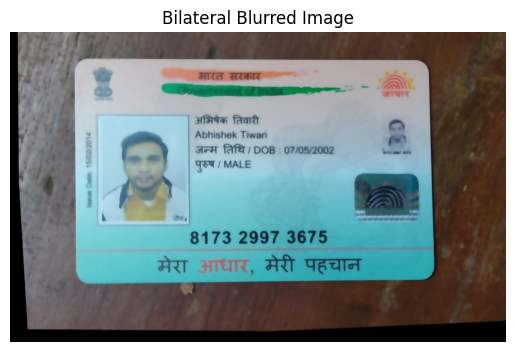

In [ ]:
blur_img = cv2.bilateralFilter(img, 9, 75, 75)
plt.figure()
plt.imshow(blur_img)
plt.title(f"Bilateral Blurred Image")
plt.axis('off')
plt.show()

**Choosing the Right Method:**

- **Mean Blur:** Good for general noise reduction but can blur edges.

- **Gaussian Blur:** Effective for removing Gaussian noise while preserving edges better than averaging.

- **Median Blur:** Excellent for removing salt-and-pepper noise and preserving edges.

- **Bilateral Filter:** Best for preserving edges and removing noise, but computationally expensive.

The choice of blurring method depends on the specific image and the desired outcome. Experiment with different parameters to achieve the desired effect.

**Additional Considerations:**

- Kernel size affects the degree of blurring. Larger kernels result in more blurring.

- Sigma values in Gaussian and bilateral filters control the extent of blurring.

- Consider using other blurring techniques like box filter, custom kernels, or morphological operations for specific applications.

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Histograms

You can consider histogram as a graph or plot, which gives you an overall idea about the intensity distribution of an image. It is a plot with pixel values (ranging from 0 to 255) in X-axis and corresponding number of pixels in the image on Y-axis.

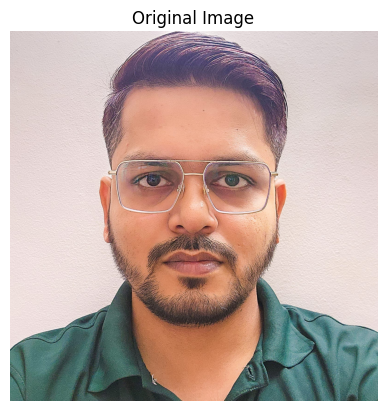

In [ ]:
face_img = cv2.imread("data/images/Intro_to_OpenCV-11.jpg")
img = cv2.cvtColor(face_img, cv2.COLOR_BGR2RGB)

plt.figure()
plt.imshow(img)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [ ]:
img.shape, img.size

((1600, 1589, 3), 7627200)

In [ ]:
# Shape after flattening the image
img.ravel().shape

(7627200,)

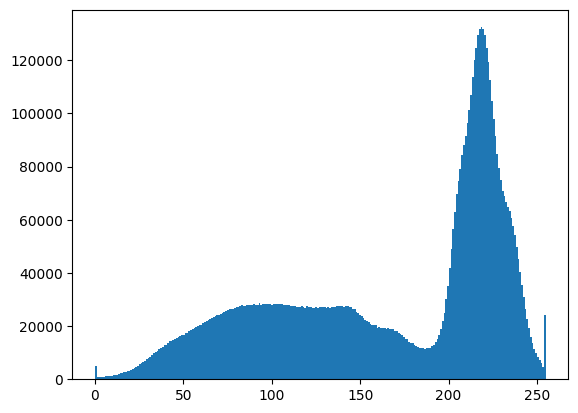

In [ ]:
# Histogram
plt.hist(img.ravel(), bins=256, range=[0, 255])
plt.show()

In [ ]:
colors = ('b', 'g', 'r')

bgr_img_ravel = [face_img[:, :, 0].ravel(), face_img[:, :, 1].ravel(), face_img[:,:, 2].ravel()]
type(bgr_img_ravel[0])

numpy.ndarray

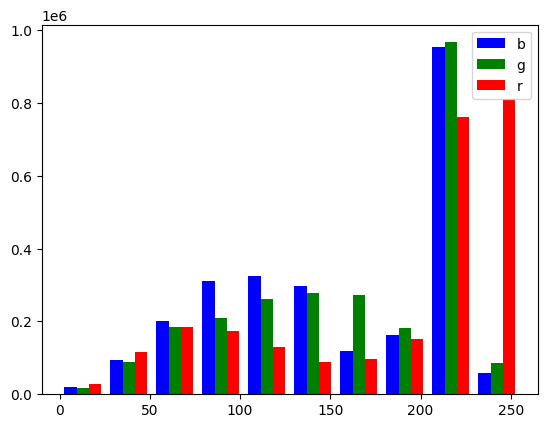

In [ ]:
plt.hist(bgr_img_ravel, color=colors, label=colors)
plt.legend()
plt.show()

We can use histograms to define the threshold for Image Segmentation to isolate the
background from an object.

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Thresholding

Thresholding is a technique in image processing that segments an image into two regions: a foreground region and a background region. It uses pixel values to do this by replacing each pixel with a black pixel if the image intensity is less than a fixed value called the threshold, and with a white pixel if the pixel intensity is greater than the threshold. The threshold can be defined either by the user or decided internally (for example, based on Histogram). Any pixel value outside the range becomes 0, and any pixel value inside the range becomes 1, or a user-defined value. The result of Thresholding is a binary image.

Different methods of Thresholding are given below:

## 1. Simple Thresholding

- Here, you have to manually supply threshold value.
- Applying Simple Thresholding methods requires human intervention. We must specify a threshold value T. All pixel intensities below T are set to 255 and all pixel intensities greater than T are set to 0.

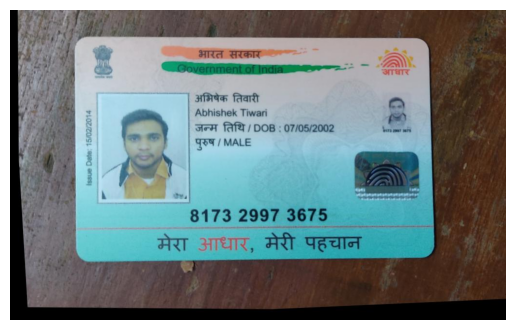

In [ ]:
# Reading image
image = cv2.imread("data/images/Intro_to_OpenCV-06.jpg")
rgb_image =  cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(rgb_image)
plt.axis("off")
plt.show()

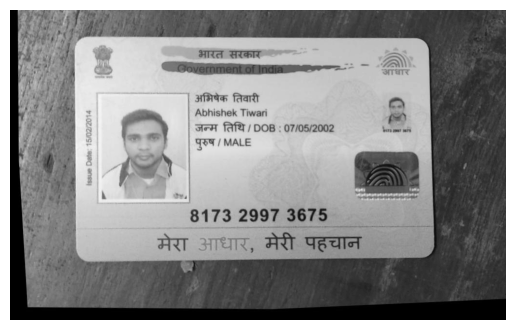

In [ ]:
# Gray Scale Conversion
gray =  cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(gray, cmap='gray')
plt.axis("off")
plt.show()

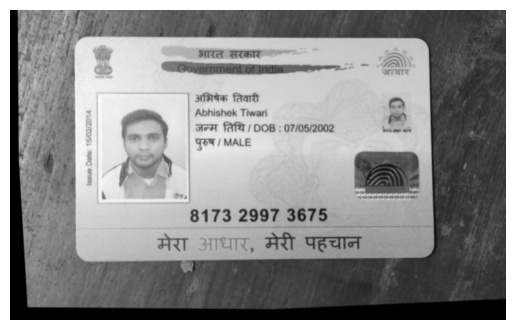

In [ ]:
blurred =  cv2.GaussianBlur(gray, (3, 3), 0)

plt.imshow(blurred, cmap='gray')
plt.axis("off")
plt.show()

After the image is blurred, we compute the thresholded image using `cv2.threshold`
function. This method requires four arguments:

1. `src`: The source image, which should be a grayscale image. We supply our blurred image as the first argument.
2. `thresh`: The threshold value used to classify the pixel values. We manually supply our threshold value as second argument. We use a value of 150.
3. `maxval`: The value to assign to the pixels that exceed the threshold.
4. `type`: The type of thresholding to apply. This determines how the thresholding is performed.

The `type` parameter specifies the type of thresholding operation. Here are the common types:

1. **`cv2.THRESH_BINARY`:**
    - Pixel value is set to `maxval` if it exceeds the threshold; otherwise, it is set to 0.
    - Formula:
    
        $\text{dst}(x, y) = \begin{cases}
            \text{maxval} & \text{if } \text{src}(x, y) > \text{thresh} \\
            0 & \text{otherwise}
        \end{cases}$

2. **`cv2.THRESH_BINARY_INV`:**
    - Pixel value is set to `maxval` if it is below the threshold; otherwise, it is set to 0.
    - Formula:

        $\text{dst}(x, y) = \begin{cases} \text{maxval} & \text{if } \text{src}(x, y) \le \text{thresh} \\ 0 & \text{otherwise} \end{cases}$

In most cases you are normally seeking your segmented objects to appear as white on a black background, hence using `cv2.THRESH_BINARY_INV`. But in the case that you want your objects to appear as black on a white background, be sure to supply the `cv2.THRESH_BINARY` flag.

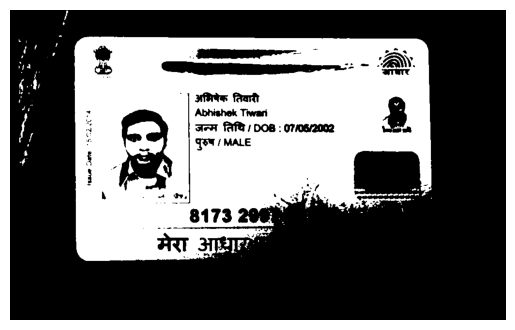

In [ ]:
T, thresh =  cv2.threshold(blurred, 150, 255, cv2.THRESH_BINARY)
plt.imshow(thresh, cmap='gray')
plt.axis("off")
plt.show()

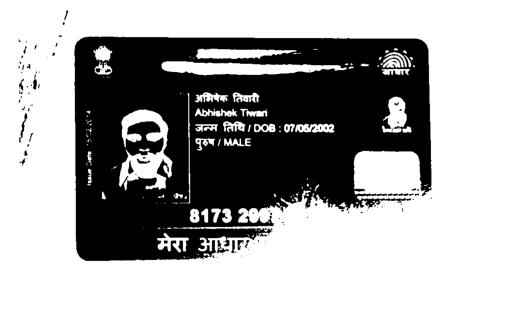

In [ ]:
T, threshInv =  cv2.threshold(blurred, 150, 255, cv2.THRESH_BINARY_INV)
plt.imshow(threshInv, cmap='gray')
plt.axis("off")
plt.show()

## 2. Otsu Thresholding

In the previous section on Simple Thresholding, we needed to manually supply a threshold value. For simple images in controlled lighting conditions, it might be feasible for us to hardcode this value.

But in real-world conditions where we do not have any a priori knowledge of the lighting conditions, we actually automatically compute an optimal value of threshold using Otsu's method.

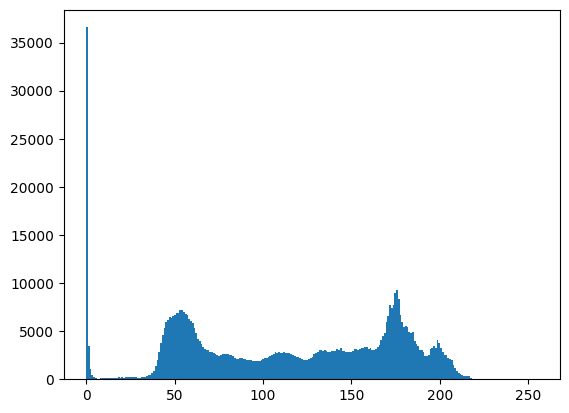

In [ ]:
# Histogram
plt.hist(gray.ravel(), bins=256, range=[0, 255])
plt.show()

Otsu's method makes the assumption that the grayscale histogram of our pixel intensities of our image is bi-modal, which simply means that the histogram has two peaks.

Notice how the histogram clearly has two peaks - the first sharp peak corresponds to the uniform background color of the image, while the second peak corresponds to the card region itself.

Otsu's thresholding value: 110.0


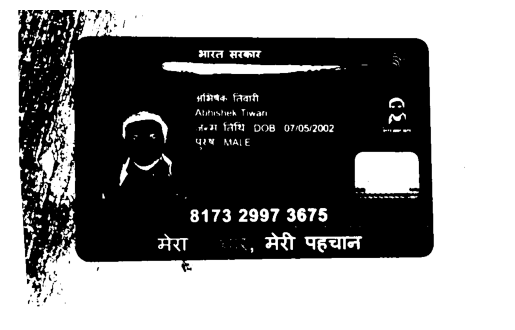

In [ ]:
(T, otsu_threshInv) = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU)

print(f"Otsu's thresholding value: {T}")

plt.imshow(otsu_threshInv, cmap='Greys_r')
plt.axis("off")
plt.show()

One of the downsides of using Simple Thresholding methods is that we need to manually supply our threshold value. Furthermore, finding a good value for threshold may require many manual experiments and parameter tunings, which is simply not practical in most situations.

To aid us in automatically determining the value of T, we leveraged Otsu's method. While Otsu's method can save us a lot of time playing the “guess and checking” game, we are left with only a single threshold value to threshold the entire image.

For simple images with controlled lighting conditions, this usually isn't a problem. But for situations when the lighting is non-uniform across the image, having only a single threshold value can seriously hurt our thresholding performance.

## 3. Adaptive Thresholding

Goal in adaptive thresholding is to statistically examine local regions of our image and determine an optimal value of T for each region — which begs the question: Which statistic do we use to compute the threshold value T for each region?

It is common practice to use either the `Arithmetic mean` or the `Gaussian mean` of the pixel intensities in each region (other methods do exist, but the Arithmetic mean and the Gaussian mean are by far the most popular).
- In the Arithmetic mean, each pixel in the neighborhood contributes equally to computing T.
- In the Gaussian mean, pixel values closer to the (x,y)-coordinate center of the region contribute more to the overall calculation of T than those farther away, due to the weights assigned by the Gaussian distribution.

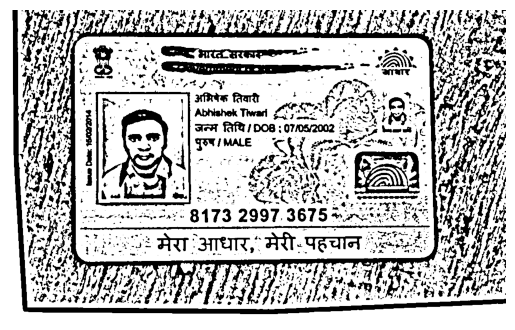

In [ ]:
adp_thresh = cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 21, 2)

plt.imshow(adp_thresh, cmap='Greys_r')
plt.axis("off")
plt.show()

The third argument is the adaptive thresholding method. Here we supply a value of `cv2.ADAPTIVE_THRESH_MEAN_C` to indicate that we are using the arithmetic mean of the local pixel neighborhood to compute our threshold value of T.

We could also supply a value of `cv2.ADAPTIVE_THRESH_GAUSSIAN_C` (which we’ll do next) to indicate we want to use the Gaussian average — which method you choose is entirely dependent on your application and situation, so you’ll want to play around with both methods.

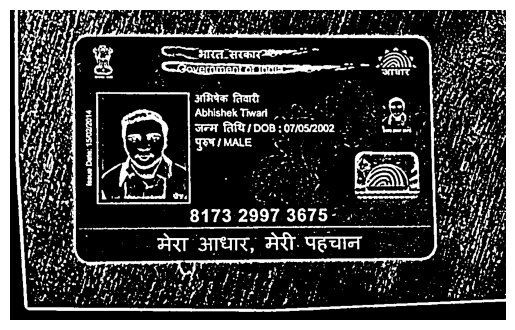

In [ ]:
thresh = cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, 21, 4)

plt.imshow(thresh, cmap='Greys_r')
plt.axis("off")
plt.show()

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Edge Detection

- An edge is a location in an image where there is a rapid change in intensity.

- We convert a 2D image (here it's a binary image) in a set of points where image intensity changes rapidly.

- Edges are very much important in terms of conveying or capturing visual information of the image.

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-12.jpg">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>Edge Detection</em>
    </td>
  </tr>
</table>

Different types of edges are illustrated below:

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-13.jpg" width="500">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>Types of edges</em>
    </td>
  </tr>
</table>

In [ ]:
otsu_threshInv.shape

(640, 1024)

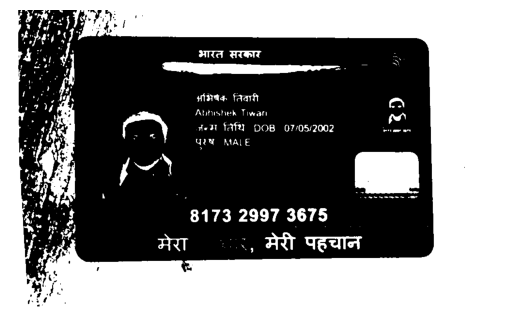

In [ ]:
plt.imshow(otsu_threshInv, cmap = 'gray')
plt.axis('off')
plt.show()

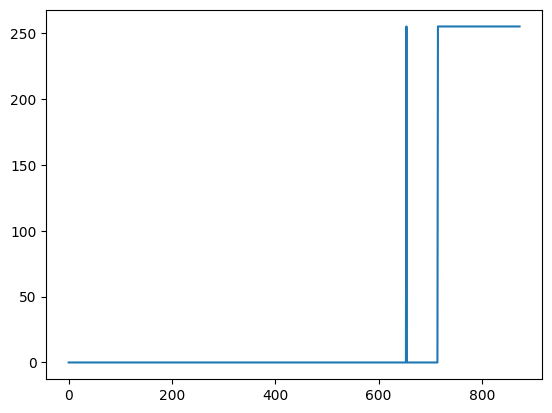

In [ ]:
# This line extracts a horizontal row of pixels (101th row) starting from the 151th column onwards from the otsu_threshInv image.
# Essentially, it extracts a horizontal line segment from the binary image.
horiz_pixels = otsu_threshInv[100, 150:]

plt.plot(horiz_pixels)
plt.show()

Due to noise in the image, real edges look like this:

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-14.jpg">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>Real edges</em>
    </td>
  </tr>
</table>

We want our Edge Detector to provide below information:
- Edge Position
- Edge Magnitude
- Edge Orientation

## 1. Edge Detection using Gradient

### 1. 1D Edge Detection

We understand that an edge represents a rapid change in image intensity within a small region. To understand the changes in pixel intensity, we can use the first-order derivative, which indicates the rate of change in a function.

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-15.jpg" width="500">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>1D Edge Detection</em>
    </td>
  </tr>
</table>

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-16.jpg" width="500">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>1D Edge Detection</em>
    </td>
  </tr>
</table>

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-17.jpg" width="500">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>1D Edge Detection</em>
    </td>
  </tr>
</table>

### 2. Discrete Gradient Operator

Let $ϵ$ be the physical distance between 2 pixels.

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-18.jpg" width="500">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>Discrete Gradient Operator</em>
    </td>
  </tr>
</table>

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-19.jpg" width="500">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>Discrete Gradient Operator</em>
    </td>
  </tr>
</table>

When we convolve the image with these 2 kernels it gives us the strength and orientation of edge along x and y axis.

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-20.jpg" width="500">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>Discrete Gradient Operator</em>
    </td>
  </tr>
</table>

When these kernels are convolved with the original image, you get an 'Edge Image'. If we use only the Vertical Kernel, the convolution yields a Sobel image, with edges enhanced in the X-direction Using the Horizontal Kernel yields a Sobel image, with edges enhanced in the Y-direction.

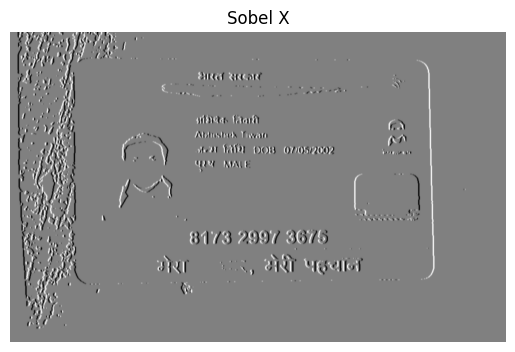

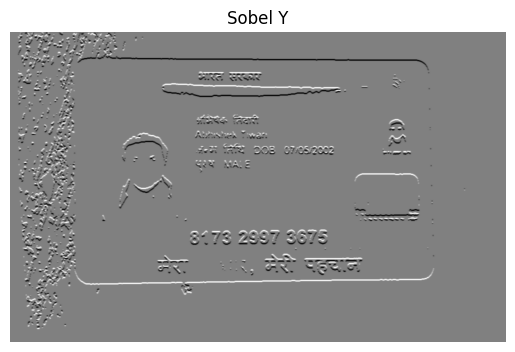

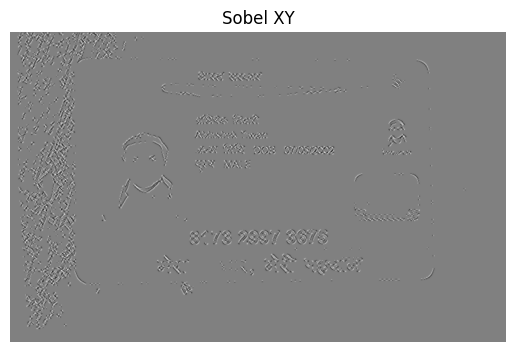

In [ ]:
# Sobel Edge Detection
sobelx = cv2.Sobel(src=otsu_threshInv, ddepth=cv2.CV_64F, dx=1, dy=0, ksize=5) #
sobely = cv2.Sobel(src=otsu_threshInv, ddepth=cv2.CV_64F, dx=0, dy=1, ksize=5) #
sobelxy = cv2.Sobel(src=otsu_threshInv, ddepth=cv2.CV_64F, dx=1, dy=1, ksize=5)

# Display Sobel Edge Detection Images
plt.imshow(sobelx, cmap = 'gray')
plt.axis('off')
plt.title('Sobel X')
plt.show()

plt.imshow(sobely, cmap = 'gray')
plt.axis('off')
plt.title('Sobel Y')
plt.show()

plt.imshow(sobelxy, cmap = 'gray')
plt.axis('off')
plt.title('Sobel XY')
plt.show()

## 2. Edge Detection using Laplacian

- Laplacian Edge Detection uses 2nd order derivatives.
- Here, we will not get peaks at the edges like 1st order derivative. Instead we have zeros $\implies$ wherever we have a zero-crossing we have an edge.
- Laplacian does not provide direction of edges.

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-21.jpg" width="500">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>Edge Detection using Laplacian</em>
    </td>
  </tr>
</table>

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-22.jpg" width="500">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>Edge Detection using Laplacian</em>
    </td>
  </tr>
</table>

## 3. Canny Edge Detection

This algorithm follows a three-stage process for extracting edges from an image. Add to it image blurring - a necessary preprocessing step to reduce noise - this makes it a four stage process, which includes:

1. Noise Reduction
2. Calculating the Intensity Gradient of the Image
3. Suppression of False Edges
4. Hysteresis Thresholding

1. **Noise Reduction:** It can be achieved using any of the Blurring methods discussed earlier.

2. **Calculating the Intensity Gradient of the Image:** Already discussed earlier under "Edge Detection using Gradient".

3. **Suppression of False Edges:** After reducing noise and calculating the intensity gradient, the algorithm in this step uses a technique called **Non-Maximum Suppression** of edges to filter out unwanted pixels (which may not actually constitute an edge). To accomplish this, each pixel is compared to its neighboring pixels. **If the gradient magnitude of the current pixel is greater than its neighboring pixels, it is left unchanged. Otherwise, the magnitude of the current pixel is set to zero.**

4. **Hysteresis Thresholding:** In this final step of Canny Edge Detection, the gradient magnitudes are compared with two threshold values, one smaller than the other.

    - If the gradient magnitude value is higher than the larger threshold value, those pixels are associated with **solid edges** and are included in the final edge map.
    - If the gradient magnitude values are lower than the smaller threshold value, the pixels are suppressed and excluded from the final edge map.
    - All the other pixels, whose gradient magnitudes fall between these two thresholds, are marked as **"weak" edges** (i.e. they become candidates for being included in the final edge map).
    - If the "weak" pixels are connected to those associated with solid edges, they are also included in the final edge map.

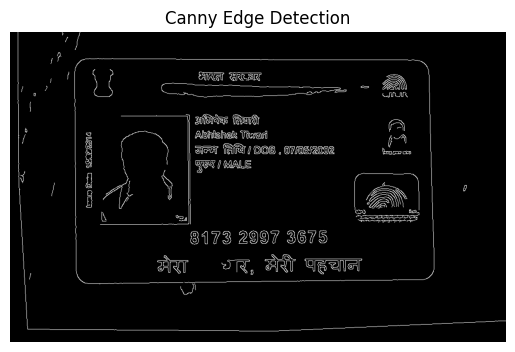

In [ ]:

# Canny Edge Detection
edges = cv2.Canny(image=blurred, threshold1=100, threshold2=200)

# Display Canny Edge Detection Image
plt.imshow(edges, cmap = 'gray')
plt.axis('off')
plt.title('Canny Edge Detection')
plt.show()

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)

# Contour Detection

- Contour is a boundary around something that has well defined edges, so the machine is able to calculate difference in gradient, and form a recognisable shape through continuing change and draw a boundary around it.

- When we join all the points on the boundary of an object, we get a contour. Typically, a specific contour refers to boundary pixels that have the same color and intensity.

- Contours are useful for shape analysis, object detection, and recognition.

## 1. cv2.findContours()



`cv2.findContours()` is a powerful function in OpenCV used to detect contours in an image.

**Arguments**
- **image:** The input image. It should be a binary image (black and white).
- **mode:** Contour retrieval mode. Specifies how contours are retrieved.
- **method:** Contour approximation method. Determines how much the contour is approximated.

**Return Values**
- **img:** Modified image
- **contours:** A Python list of all the contours in the image. Each individual contour is a NumPy array of (x,y) coordinates of boundary points of the object.
- **hierarchy:** An optional output array containing information about the hierarchical relationship between contours.

**What is Hierarchy?**

Function `cv2.findContours()` not only returns the contours found in an image but also returns valuable information about the hierarchy of the contours in the image. The hierarchy encodes how the contours may be arranged in the image, e.g, they may be nested within another contour. In this case, we call outer one as **parent** and inner one as **child.** Often we are more interested in some contours than others. For example, you may only want to retrieve the external contour of an object. Using the Retrieval Modes specified, the `cv2.findContours()` function can determine how the contours are to be returned or arranged in a hierarchy.

<table>
  <tr>
    <td align="center">
      <img src="https://raw.githubusercontent.com/ancilcleetus/AI-Learning-Lab/refs/heads/main/Tools/OpenCV/Intro-to-OpenCV-by-CampusX/data/images/Intro_to_OpenCV-23.jpg" width="500">
    </td>
  </tr>
  <tr>
    <td align="center">
      <em>Example Image for Contour Detection</em>
    </td>
  </tr>
</table>

Now see above figure, where the contours associated with each shape have been identified. Each of the numbers in above figure have a significance.

In this image, there are a few shapes which are numbered from 0-5. 2 and 2a denotes the external and internal contours of the outermost box.

Here, contours 0,1,2 are external or outermost. We can say, they are in hierarchy-0 or simply they are in same hierarchy level.

Next comes contour-2a. It can be considered as a child of contour-2 (or in opposite way, contour-2 is parent of contour-2a). So let it be in hierarchy-1.

Similarly, contour-3 is child of contour-2 and it comes in next hierarchy.

Finally contours 4,5 are the children of contour-3a, and they come in the last hierarchy level. From the way I numbered the boxes, I would say contour-4 is the first child of contour-3a (It can be contour-5 also).

### 1. Contour Retrieval Modes

- **cv2.RETR_EXTERNAL:** Retrieves only the external contours.

- **cv2.RETR_LIST:** Retrieves all contours without hierarchical relationships.

- **cv2.RETR_CCOMP:** Retrieves all contours and organizes them into two levels of hierarchy: external and internal.

- **cv2.RETR_TREE:** Retrieves all contours and reconstructs a full hierarchy of nested contours.

### 2. Contour Approximation Modes

Detected contours can be compressed to reduce the number of points. In this sense, OpenCV provides sevaral methods to reduce the number of points.

- **CHAIN_APPROX_SIMPLE:** This is faster, approximates the contour and compresses horizontal, vertical, and diagonal segments, keeping only their end points.

- **CHAIN_APPROX_NONE:** This retains all the original contour points, making it suitable when precise contour representation is required, but it might be slower and consume more memory compared to CHAIN_APPROX_SIMPLE.

contours: (133, 55, 743, 465)
Area: 335355.0


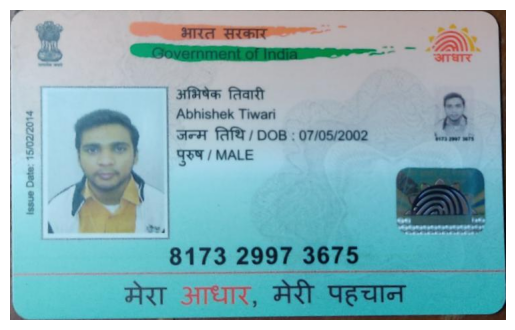

In [ ]:
contours, _ = cv2.findContours(adp_thresh, mode = cv2.RETR_EXTERNAL, method = cv2.CHAIN_APPROX_SIMPLE)

# Select the largest contour (assuming the ID card is the largest object)
largest_contour = None
largest_area = 0
for cnt in contours:
    area = cv2.contourArea(cnt)
    if area > largest_area:
        largest_contour = cnt
        largest_area = area

x, y, w, h = cv2.boundingRect(largest_contour)

print(f"contours: {(x, y, w, h)}")
print(f"Area: {largest_area}")

contour_id = rgb_image[y:y+h, x:x+w]

plt.imshow(contour_id)
plt.axis('off')
plt.show()

Thus, we have successfully cropped ID Card from the image using Contour Detection.

![rainbow](https://github.com/ancilcleetus/My-Learning-Journey/assets/25684256/839c3524-2a1d-4779-85a0-83c562e1e5e5)